# **Projeto de IA - Aprendizado de Máquina**

**Grupo:**

Pedro Henrique Coelho Ponte

Yago Lobo Ximenes

Renan Ferreira Rodrigues

## **O conjunto de dados**

### Origem e domínio

O **mfeat-fourier** é uma das seis *views* do **Multiple Features Dataset (mfeat)**, doado por Robert P. W. Duin (Department of Applied Physics, Delft University of Technology) ao UCI Machine Learning Repository.

Os dados são **numerais manuscritos (0–9) extraídos de uma coleção de mapas de serviços públicos holandeses**, digitalizados em imagens binárias. As imagens originais **foram perdidas**; segundo a documentação, versões amostradas em 15 × 16 pixels ainda podem ser obtidas a partir da view `mfeat-pix`, recurso que utilizaremos na análise de erros para visualizar os casos mal classificados.

### Um conjunto multi-view

Os mesmos 2 000 caracteres foram descritos por seis conjuntos de atributos distintos:

| View | Atributos | Descrição |
|---|---|---|
| `mfeat-fou` | **76** | Coeficientes de Fourier do contorno — **utilizada neste trabalho** |
| `mfeat-fac` | 216 | Correlações de perfil |
| `mfeat-kar` | 64 | Coeficientes de Karhunen-Loève |
| `mfeat-pix` | 240 | Médias de pixel em janelas 2 × 3 |
| `mfeat-zer` | 47 | Momentos de Zernike |
| `mfeat-mor` | 6 | Atributos morfológicos |

Este trabalho utiliza **apenas a view `fou`**, reportada na literatura como uma das mais fracas quando tomada isoladamente e estudaremos o porquê disso. Ela busca prever o dígito representado utilizando 76 atributos no total.

### O que são os 76 atributos

São **descritores de Fourier do contorno** do caractere. A leitura padrão na literatura de descritores de forma é que se trata das **magnitudes** dos coeficientes da transformada de Fourier discreta do contorno, normalizadas em escala e com a fase descartada, o que confere invariância a translação, escala, rotação e ponto inicial do traçado. Os valores observados no arquivo (todos não-negativos e limitados a um intervalo estreito) são coerentes com essa interpretação.

A principal consequência dessa invariância é a **impossibilidade, em princípio, de distinguir formas que sejam rotações uma da outra**, ou seja, os dígitos "6" e "9" podem causar ambiguidade forte. Essa hipótese é desenvolvida e testada empiricamente na seção de análise dos erros.

In [42]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.io.arff import loadarff

ARFF_PATH = Path("dataset_14_mfeat-fourier.arff")

# loadarff devolve (structured ndarray, MetaData).
raw, meta = loadarff(ARFF_PATH)
df = pd.DataFrame(raw)

# A classe 1 representa o digito 0 e assim por diante, logo faz-se a transformação de classe para digito.
df["class"] = df["class"].str.decode("utf-8").astype(int)
df["digit"] = df["class"] - 1

FEATURES = [c for c in df.columns if c.startswith("att")]

X = df[FEATURES].astype(np.float64)
y = df["digit"]  # 0..9, o dígito de fato representado

print(f"X: {X.shape}   y: {y.shape}")
print(f"Atributos: {FEATURES[0]} ... {FEATURES[-1]}")
print(f"Tipos distintos em X: {sorted(set(X.dtypes.astype(str)))}")
print(f"Rótulos brutos no arquivo: {sorted(df['class'].unique().tolist())}")
print(f"Dígitos após a conversão:  {sorted(y.unique().tolist())}")

X: (2000, 76)   y: (2000,)
Atributos: att1 ... att76
Tipos distintos em X: ['float64']
Rótulos brutos no arquivo: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Dígitos após a conversão:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [43]:
# Características descritivas, todas calculadas a partir dos dados carregados.
n_inst, n_attr = X.shape
n_classes = y.nunique()
contagem = y.value_counts().sort_index()

n_faltantes = int(X.isna().sum().sum())
n_duplicatas = int(X.duplicated().sum())

desvios = X.std()
minimos, maximos = X.min(), X.max()

print(f"Instâncias .................. {n_inst}")
print(f"Atributos preditivos ........ {n_attr}, Tipos de dados: {X.dtypes.value_counts().to_dict()}")
print(f"Classes ..................... {n_classes}")
print(f"Valores faltantes ........... {n_faltantes}")
print(f"Linhas duplicadas ........... {n_duplicatas}")
print(f"Faixa global dos valores .... [{minimos.min():.4f}, {maximos.max():.4f}]")
print(f"Desvio-padrão por atributo .. {desvios.min():.4f} ({desvios.idxmin()}) a "f"{desvios.max():.4f} ({desvios.idxmax()})")
print(f"Instâncias por atributo ..... {n_inst / n_attr:.1f}")

# Checagem se duplicatas produzem mesma classe.
dup = X.duplicated(keep=False)
if dup.any():
    chave = pd.Series(list(map(tuple, X[dup].to_numpy())), index=X.index[dup])
    rotulos_por_grupo = df.loc[dup, "digit"].groupby(chave).nunique()
    print(
        f"\nGrupos de linhas idênticas .. {len(rotulos_por_grupo)} "
        f"| com rótulos divergentes: {int((rotulos_por_grupo > 1).sum())}"
    )

print("\nInstâncias por dígito:")
print(contagem.to_string())

Instâncias .................. 2000
Atributos preditivos ........ 76, Tipos de dados: {dtype('float64'): 76}
Classes ..................... 10
Valores faltantes ........... 0
Linhas duplicadas ........... 6
Faixa global dos valores .... [0.0002, 0.7965]
Desvio-padrão por atributo .. 0.0376 (att46) a 0.1762 (att2)
Instâncias por atributo ..... 26.3

Grupos de linhas idênticas .. 6 | com rótulos divergentes: 0

Instâncias por dígito:
digit
0    200
1    200
2    200
3    200
4    200
5    200
6    200
7    200
8    200
9    200


### Discussão das características

**Balanceamento.** O conjunto é perfeitamente balanceado: exatamente 200 instâncias por dígito. Ainda assim reportaremos F1-macro e a matriz de confusão, além da acurácia, porque o interesse não é apenas o acerto global, mas onde os erros se concentram.

**Qualidade.** Não há valores faltantes, o que elimina toda a etapa de imputação. Existem 6 pares de linhas exatamente duplicadas, e verificamos que **todos têm rótulos concordantes**, não há, portanto, ruído de rótulo por essa via. A decisão de removê-las ou mantê-las é discutida na seção de pré-processamentos.

**Ordenação do arquivo.** As instâncias estão dispostas em **blocos contíguos por classe** (as 200 primeiras são o dígito 0, as 200 seguintes o dígito 1, e assim por diante). Todas as validações cruzadas deste trabalho usam, por isso, embaralhamento das instâncias.

**Rótulos deslocados.** O atributo alvo é declarado no arquivo como nominal com valores `1..10`, e não `0..9`. Combinado com a ordenação acima, o mapeamento correto é **classe *k* = dígito *k*−1**. Fazemos essa conversão já na carga, para que matrizes de confusão e discussões se refiram ao dígito de fato representado.

**Dimensionalidade.** São 76 atributos para 2 000 instâncias, razão global de ~26 amostras por atributo. Na verdade, a leitura mais relevante é por classe: 200 instâncias ÷ 76 atributos ≈ 2,6, bem abaixo da regra de bolso de ao menos 10 amostras por atributo por classe. Não se trata de um caso extremo de alta dimensionalidade, mas é apertado o suficiente para prever dificuldade em modelos com muitos parâmetros a estimar. Resta saber se a dimensionalidade *efetiva* é menor que 76 — ou seja, se os atributos são redundantes entre si a ponto de permitir compressão. Trata-se de uma hipótese a ser verificada, e a análise exploratória a seguir a testa diretamente.

**Escala.** Todos os atributos são contínuos, não-negativos e de magnitude comparável, mas não idêntica: os desvios-padrão variam por um fator de ~4,7. Como a distância euclidiana soma *quadrados*, o atributo de maior dispersão acaba pesando cerca de 22 vezes mais que o de menor em qualquer decisão baseada em distância, sem ser mais informativo por isso. A padronização é, portanto, necessária, e sua implementação é detalhada na seção de pré-processamentos.

## **Análise exploratória dos dados**

#### Paleta de cores

In [44]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.preprocessing import StandardScaler

# Sistema visual único para todas as figuras da seção. As figuras do notebook são
# imagens estáticas, então apenas o modo claro se aplica.
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
AZUL, LARANJA, VERMELHO = "#2a78d6", "#eb6834", "#e34948"
NEUTRO, FUNDO_PONTO = "#f0efec", "#d6d5cf"

# Sequencial: um único matiz, claro -> escuro (magnitude).
RAMPA_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_azul", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])
# Divergente: dois matizes opostos com cinza neutro no meio (polaridade em torno de 0).
RAMPA_DIV = mpl.colors.LinearSegmentedColormap.from_list(
    "div_azul_vermelho", [AZUL, "#9ec5f4", NEUTRO, "#f0a3a2", VERMELHO])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.grid": True, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})


#### Padronização dos dados
Sem ela, as análises seriam enviesadas por atributos com maior dispersão.

In [45]:
Z = StandardScaler().fit_transform(X.to_numpy())
yv = y.to_numpy()

print(f"Z: {Z.shape} | média {Z.mean():+.1e} | desvio {Z.std():.3f}")

Z: (2000, 76) | média -1.7e-17 | desvio 1.000


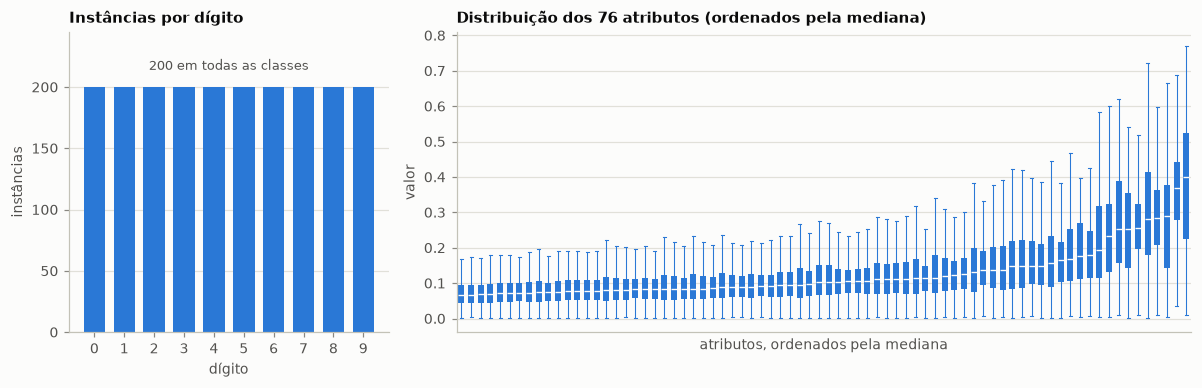

Assimetria por atributo: mediana 0.55 | máx 1.03 | 1 de 76 acima de 1
Outliers (1,5·IQR): 1.00% das células
  instâncias com >=1 atributo sinalizado: 660 (esperado ao acaso ~1068)
  instâncias com >=10 atributos sinalizados: 2


In [46]:
from scipy.stats import skew

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.3]})

ax1.bar(contagem.index, contagem.values, color=AZUL, width=0.72)
ax1.set_title("Instâncias por dígito", loc="left", fontsize=10, weight="bold")
ax1.set(xlabel="dígito", ylabel="instâncias", xticks=range(10), ylim=(0, 245))
ax1.grid(axis="x", visible=False)
ax1.annotate("200 em todas as classes", xy=(4.5, 214), ha="center", fontsize=8.5, color=INK2)

ordem = X.median().sort_values().index
ax2.boxplot(
    [X[c] for c in ordem], widths=0.62, showfliers=False, patch_artist=True,
    medianprops=dict(color=SURFACE, linewidth=0.9),
    whiskerprops=dict(color=AZUL, linewidth=0.7),
    capprops=dict(color=AZUL, linewidth=0.7),
    boxprops=dict(facecolor=AZUL, edgecolor="none"),
)
ax2.set_title("Distribuição dos 76 atributos (ordenados pela mediana)",
              loc="left", fontsize=10, weight="bold")
ax2.set(xlabel="atributos, ordenados pela mediana", ylabel="valor", xticks=[])
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

s = skew(X.to_numpy(), axis=0)
q1, q3 = np.percentile(X.to_numpy(), [25, 75], axis=0)
iqr = q3 - q1
fora = (X.to_numpy() < q1 - 1.5 * iqr) | (X.to_numpy() > q3 + 1.5 * iqr)
esperado = n_inst * (1 - 0.99 ** n_attr)

print(f"Assimetria por atributo: mediana {np.median(s):.2f} | máx {s.max():.2f} "
      f"| {(s > 1).sum()} de {n_attr} acima de 1")
print(f"Outliers (1,5·IQR): {100 * fora.mean():.2f}% das células")
print(f"  instâncias com >=1 atributo sinalizado: {(fora.sum(1) > 0).sum()} "
      f"(esperado ao acaso ~{esperado:.0f})")
print(f"  instâncias com >=10 atributos sinalizados: {(fora.sum(1) >= 10).sum()}")

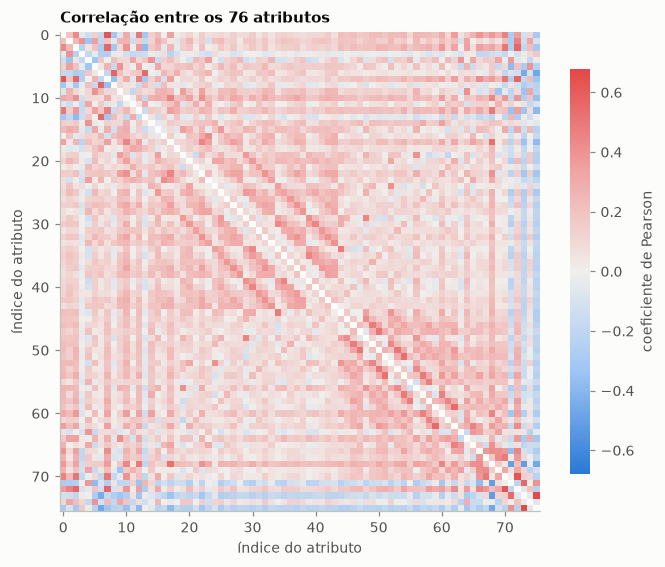

|corr| média (todos os 2850 pares): 0.146 | mediana 0.127
|corr| média entre adjacentes (k, k+1): 0.135
|corr| máxima: 0.679


In [47]:
Corr = np.corrcoef(Z.T)
fora_diag = Corr[np.triu_indices(n_attr, 1)]
lim = np.abs(fora_diag).max()

# A diagonal (sempre 1,0) é mascarada para não degradar a escala.
Cm = Corr.copy()
np.fill_diagonal(Cm, np.nan)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
cmap = RAMPA_DIV.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(Cm, cmap=cmap, vmin=-lim, vmax=lim)  # escala simétrica em torno de 0
ax.set_title("Correlação entre os 76 atributos", loc="left", fontsize=10, weight="bold")
ax.set(xlabel="índice do atributo", ylabel="índice do atributo")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.82)
cb.set_label("coeficiente de Pearson", color=INK2)
cb.outline.set_visible(False)

plt.tight_layout()
plt.show()

adj = np.array([Corr[i, i + 1] for i in range(n_attr - 1)])
print(f"|corr| média (todos os {len(fora_diag)} pares): {np.abs(fora_diag).mean():.3f} "
      f"| mediana {np.median(np.abs(fora_diag)):.3f}")
print(f"|corr| média entre adjacentes (k, k+1): {np.abs(adj).mean():.3f}")
print(f"|corr| máxima: {np.abs(fora_diag).max():.3f}")

#### Componentes principais
Quantos eixos ortogonais são precisos para reter a variação dos 76 atributos.

In [48]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(Z)
vr = pca_full.explained_variance_ratio_
cum = np.cumsum(vr)
k90, k95 = np.searchsorted(cum, 0.90) + 1, np.searchsorted(cum, 0.95) + 1
pr = pca_full.explained_variance_.sum() ** 2 / (pca_full.explained_variance_ ** 2).sum()

print("Componentes necessários por limiar de variância:")
for t in (0.5, 0.8, 0.9, 0.95, 0.99):
    print(f"  {t:.0%} -> {np.searchsorted(cum, t) + 1:2d} de {n_attr}")

Componentes necessários por limiar de variância:
  50% -> 11 de 76
  80% -> 33 de 76
  90% -> 47 de 76
  95% -> 58 de 76
  99% -> 71 de 76


#### Há correlação entre atributos, porém ela não é linear nem monotônica.
Sabemos que os atributos são calculados em cima de um mesmo contorno contínuo, logo intuitivamente desconfiamos que havia correlação entre eles. Testamos a correlação de Pearson e Spearman, porém elas foram baixas. Investigamos então dCor(correlação geral) e descobrimos que há correlação, não identificada pelos métodos anteriores.

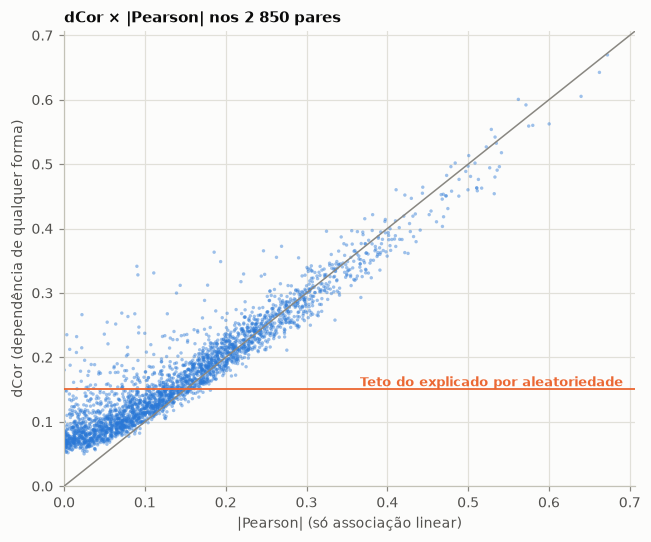

|Pearson |: média 0.150 | máx 0.672
|Spearman|: média 0.140 | máx 0.652  -> sem não linearidade monotônica

dCor           : média 0.175 | máx 0.670
dCor sob o nulo: média 0.075 | máx 0.150
pares acima do teto do nulo: 1470 de 2850
entre os 2023 pares com |Pearson|<0,2, dCor máx = 0.363

Excesso sobre o nulo, ambos com n=200 — global +0.079 | dentro da classe +0.084
  -> iguais: a dependência é dos atributos, não da mistura de classes


In [49]:
from scipy.stats import spearmanr

rng = np.random.default_rng(0)


def _dist_centrada(v):
    A = np.abs(v[:, None] - v[None, :])
    return A - A.mean(0, keepdims=True) - A.mean(1, keepdims=True) + A.mean()


def dcor_matriz(M):
    """dCor entre todas as colunas de M. Empilhar as matrizes duplo-centradas e fazer um
    único produto Ac @ Ac.T.
    """
    n, p = M.shape
    Ac = np.stack([_dist_centrada(M[:, j]).ravel() for j in range(p)])
    dcov2 = (Ac @ Ac.T) / (n * n)
    d = np.sqrt(np.maximum(np.diag(dcov2), 1e-300))
    return np.sqrt(np.maximum(dcov2, 0)) / np.sqrt(np.outer(d, d))


iu = np.triu_indices(n_attr, 1)
amostra = rng.choice(n_inst, 500, replace=False)
dcor = dcor_matriz(Z[amostra])[iu]
Zperm = np.column_stack([rng.permutation(Z[amostra][:, j]) for j in range(n_attr)])
dcor_nulo = dcor_matriz(Zperm)[iu]
teto_nulo = dcor_nulo.max()

pearson_abs_amostra = np.abs(np.corrcoef(Z[amostra], rowvar=False)[iu])
spear = np.abs(spearmanr(Z).statistic[iu])

fig, ax2 = plt.subplots(figsize=(6, 5))

ax2.scatter(pearson_abs_amostra, dcor, s=5, c=AZUL, edgecolors="none", alpha=0.45, zorder=2)

lim = max(pearson_abs_amostra.max(), dcor.max()) * 1.05
ax2.plot([0, lim], [0, lim], color=MUTED, linewidth=1, zorder=3)

ax2.axhline(teto_nulo, color=LARANJA, linewidth=1.2, zorder=3)
ax2.annotate("Teto do explicado por aleatoriedade", xy=(lim * 0.98, teto_nulo), ha="right",
             va="bottom", fontsize=8.5, color=LARANJA, weight="bold")

ax2.set_title("dCor × |Pearson| nos 2 850 pares", loc="left", fontsize=10, weight="bold")
ax2.set(xlabel="|Pearson| (só associação linear)",
        ylabel="dCor (dependência de qualquer forma)", xlim=(0, lim), ylim=(0, lim))

plt.tight_layout()
plt.show()

print(f"|Pearson |: média {pearson_abs_amostra.mean():.3f} | máx {pearson_abs_amostra.max():.3f}")
print(f"|Spearman|: média {spear.mean():.3f} | máx {spear.max():.3f}"
      f"  -> sem não linearidade monotônica")
print(f"\ndCor           : média {dcor.mean():.3f} | máx {dcor.max():.3f}")
print(f"dCor sob o nulo: média {dcor_nulo.mean():.3f} | máx {teto_nulo:.3f}")
print(f"pares acima do teto do nulo: {(dcor > teto_nulo).sum()} de {len(dcor)}")
fraco = pearson_abs_amostra < 0.2
print(f"entre os {fraco.sum()} pares com |Pearson|<0,2, dCor máx = {dcor[fraco].max():.3f}")

def excesso(M):
    Mp = np.column_stack([rng.permutation(M[:, j]) for j in range(n_attr)])
    return dcor_matriz(M)[iu].mean() - dcor_matriz(Mp)[iu].mean()


exc_global = excesso(Z[rng.choice(n_inst, 200, replace=False)])
exc_classe = [excesso(Z[yv == k]) for k in range(10)]
print(f"\nExcesso sobre o nulo, ambos com n=200 — global {exc_global:+.3f} | "
      f"dentro da classe {np.mean(exc_classe):+.3f}")
print("  -> iguais: a dependência é dos atributos, não da mistura de classes")

**O que isso mostra.**

1. **Existe dependência não linear real entre os atributos.** Pearson e Spearman ficam baixos, sugerindo pouca associação — mas a dCor revela que 1 470 dos 2 850 pares ficam acima do teto explicável por aleatoriedade (nulo por permutação). Como Spearman (que capta monotonicidade) também é baixo, a dependência não é sequer monotônica — é uma relação mais complexa, que só a dCor detecta.
2. **Não é um artefato da mistura de classes.** O excesso de dCor sobre o nulo é praticamente igual quando medido no conjunto todo ou dentro de cada dígito separadamente — ou seja, a dependência vem da forma como os atributos são calculados (todos a partir do mesmo contorno), não de uma correlação espúria criada pela mistura de 10 dígitos diferentes.

**Consequência.** Isso mostra que os atributos guardam estrutura que os métodos lineares (Pearson, e por extensão o PCA) não enxergam — mas não diz, por si só, se essa estrutura é aproveitável por um classificador ou por uma redução de dimensionalidade não linear. Essa é uma pergunta empírica, deixada para a etapa de modelagem: lá, `n_components` (incluindo a opção de não reduzir) entra como hiperparâmetro a ser testado, em vez de uma escolha decidida agora pela EDA.

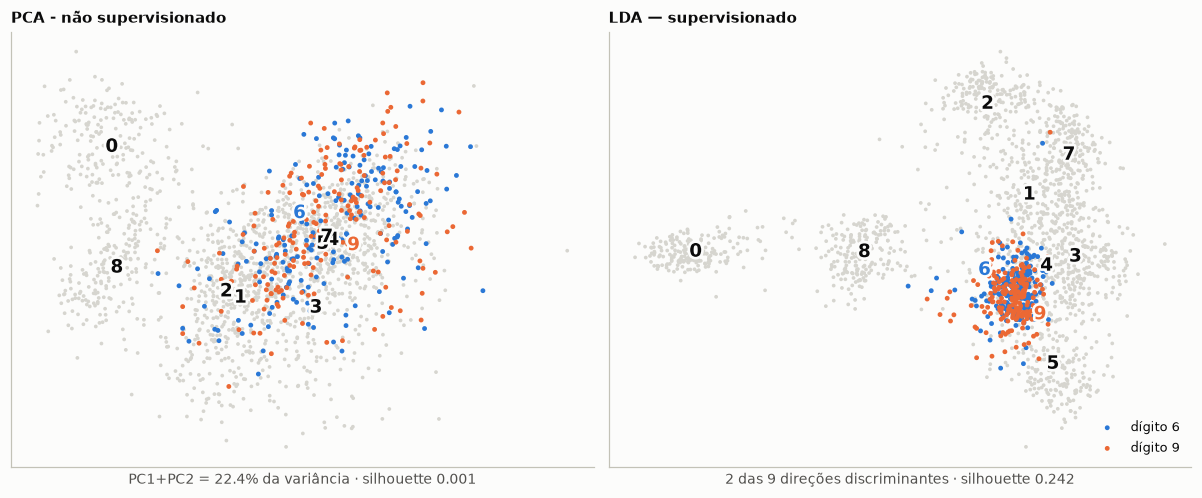

In [50]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score

DESTAQUE = {6: AZUL, 9: LARANJA}


def scatter_digitos(ax, P, titulo, sub):
    outros = ~np.isin(yv, list(DESTAQUE))
    ax.scatter(P[outros, 0], P[outros, 1], s=6, c=FUNDO_PONTO, edgecolors="none", zorder=1)
    for d, cor in DESTAQUE.items():
        m = yv == d
        ax.scatter(P[m, 0], P[m, 1], s=10, c=cor, edgecolors="none", zorder=3,
                   label=f"dígito {d}")

    # Os centroides de 6 e 9 quase coincidem, logo os afastamos para melhor legibilidade.
    dx = 0.055 * np.ptp(P[:, 0])
    desloc = {6: (-dx, 0.55 * dx), 9: (dx, -0.55 * dx)}
    for d in range(10):
        cx, cy = P[yv == d].mean(0)
        ox, oy = desloc.get(d, (0.0, 0.0))
        ax.text(cx + ox, cy + oy, str(d), fontsize=12, weight="bold",
                ha="center", va="center", color=DESTAQUE.get(d, INK), zorder=4,
                path_effects=[pe.withStroke(linewidth=3.5, foreground=SURFACE)])
    ax.set_title(titulo, loc="left", fontsize=10, weight="bold")
    ax.set_xlabel(sub)
    ax.set(xticks=[], yticks=[])


P_pca = PCA(n_components=2, random_state=0).fit_transform(Z)
P_lda = LinearDiscriminantAnalysis(n_components=2).fit(Z, yv).transform(Z)

sil_76 = silhouette_score(Z, yv)
sil_pca = silhouette_score(P_pca, yv)
sil_lda = silhouette_score(P_lda, yv)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
scatter_digitos(ax1, P_pca, "PCA - não supervisionado",
                f"PC1+PC2 = {vr[:2].sum():.1%} da variância · silhouette {sil_pca:.3f}")
scatter_digitos(ax2, P_lda, "LDA — supervisionado",
                f"2 das 9 direções discriminantes · silhouette {sil_lda:.3f}")
ax2.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

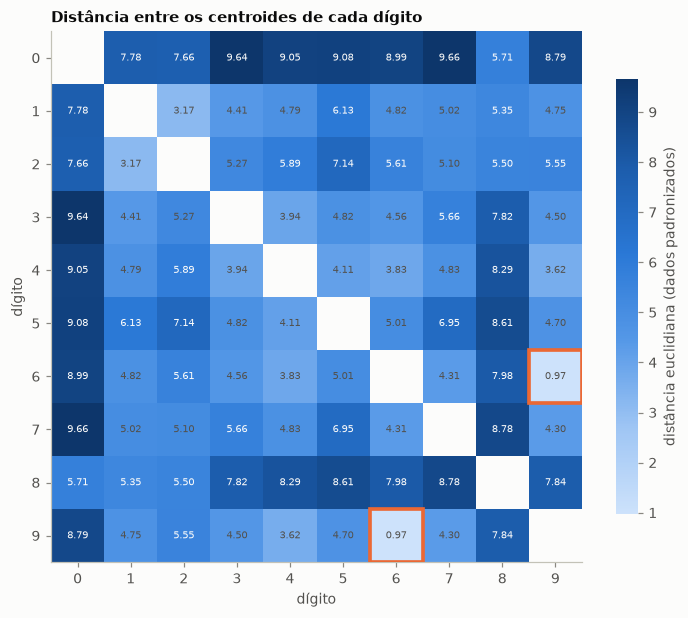

Pares de dígitos mais próximos:
  6 e 9: 0.97
  1 e 2: 3.17
  4 e 9: 3.62
  4 e 6: 3.83


In [51]:
from scipy.spatial.distance import pdist, squareform

# Centroide da classe k: o vetor médio das suas 200 instâncias — um ponto em R^76,
# o "espectro de forma médio" daquele dígito. Colapsa 200 pontos em 1.
centroides = np.array([Z[yv == k].mean(axis=0) for k in range(10)])
D = squareform(pdist(centroides))

fig, ax = plt.subplots(figsize=(6.8, 5.6))
Dm = D.copy()
np.fill_diagonal(Dm, np.nan)
cmap = RAMPA_SEQ.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(Dm, cmap=cmap)  # sequencial: um matiz, claro -> escuro (magnitude)

for i in range(10):
    for j in range(10):
        if i == j:
            continue
        v = D[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.8,
                color=SURFACE if v > np.nanmax(Dm) * 0.55 else INK2)

# O par 6-9 é o achado: destacado por moldura, não por cor — a cor já codifica magnitude.
for (i, j) in [(6, 9), (9, 6)]:
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False,
                               edgecolor=LARANJA, linewidth=2.4, zorder=5))

ax.set_title("Distância entre os centroides de cada dígito", loc="left",
             fontsize=10, weight="bold")
ax.set(xticks=range(10), yticks=range(10), xlabel="dígito", ylabel="dígito")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.82)
cb.set_label("distância euclidiana (dados padronizados)", color=INK2)
cb.outline.set_visible(False)

plt.tight_layout()
plt.show()

pares = sorted((D[i, j], i, j) for i in range(10) for j in range(i + 1, 10))
print("Pares de dígitos mais próximos:")
for d, i, j in pares[:4]:
    print(f"  {i} e {j}: {d:.2f}")

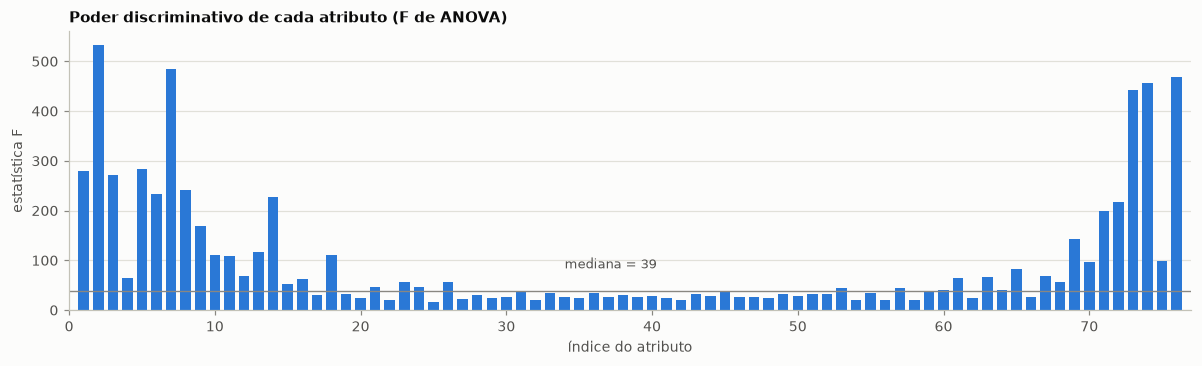

F por atributo: mín 16 | mediana 39 | máx 533
F médio por faixa de índice:
  att 1-19:   183
  att20-38:    32
  att39-57:    30
  att58-76:   139

10 atributos mais discriminativos: ['att2', 'att7', 'att76', 'att74', 'att73', 'att5', 'att1', 'att3', 'att8', 'att6']

Teste do pareamento espelhado (i, 77-i): |corr| média 0.143 vs 0.146 da linha de base -> sem evidência


In [52]:
from sklearn.feature_selection import f_classif

F_score, _ = f_classif(X.to_numpy(), yv)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(1, n_attr + 1), F_score, color=AZUL, width=0.72)
ax.axhline(np.median(F_score), color=MUTED, linewidth=0.9, zorder=1)
ax.annotate(f"mediana = {np.median(F_score):.0f}", xy=(38, np.median(F_score)),
            xytext=(34, np.median(F_score) + 45), fontsize=8.5, color=INK2)
ax.set_title("Poder discriminativo de cada atributo (F de ANOVA)",
             loc="left", fontsize=10, weight="bold")
ax.set(xlabel="índice do atributo", ylabel="estatística F", xlim=(0, n_attr + 1))
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"F por atributo: mín {F_score.min():.0f} | mediana {np.median(F_score):.0f} "
      f"| máx {F_score.max():.0f}")
print("F médio por faixa de índice:")
for lo, hi in [(0, 19), (19, 38), (38, 57), (57, 76)]:
    print(f"  att{lo + 1:2d}-{hi:2d}: {F_score[lo:hi].mean():5.0f}")
print(f"\n10 atributos mais discriminativos: "
      f"{[f'att{i + 1}' for i in np.argsort(F_score)[::-1][:10]]}")

# Teste da conjectura de que os extremos seriam pares +k/-k de um mesmo harmônico.
espelho = [Corr[i, n_attr - 1 - i] for i in range(n_attr // 2)]
print(f"\nTeste do pareamento espelhado (i, {n_attr + 1}-i): "
      f"|corr| média {np.mean(np.abs(espelho)):.3f} "
      f"vs {np.abs(fora_diag).mean():.3f} da linha de base -> sem evidência")

### Síntese da análise exploratória

| Achado | Evidência | Consequência |
|---|---|---|
| Balanceamento perfeito, sem faltantes | 200 por classe; 0 faltantes | acurácia é métrica honesta; sem imputação |
| Sem problema de outliers | 1% das células (taxa esperada); só 2 instâncias com ≥10 | não remover; justificar |
| Assimetria branda | mediana 0,55; 1 de 76 acima de 1 | **não** transformar (log/Box-Cox) |
| Escalas desiguais | razão de desvios 4,7× | padronizar, dentro do `Pipeline` |
| **Sem redundância _linear_** | \|corr\| média 0,146; máx 0,679; nenhum par > 0,8 | Pearson sozinho não decide a questão |
| **Redundância não linear, grande** | dCor acima do nulo em 1470 de 2850 pares; excesso igual dentro e fora das classes | Pearson e PCA são cegos a ela; se é aproveitável fica em aberto |
| **PCA pouco compressivo** | 58 de 76 componentes para 95% | `n_components` é hiperparâmetro, não escolha *a priori* |
| Contribuição desigual dos atributos | perfil em U; metade com F ≈ 30 | seleção de atributos como alternativa ao PCA |
| **Classes fortemente sobrepostas** | silhouette 0,038 com rótulos verdadeiros | a dificuldade do conjunto está aqui |
| **6 e 9 quase coincidentes** | centroides a 0,97 — 1º de 45, 3,3× à frente do 2º; fundidos em LDA e t-SNE | limitação da *representação*; teto de desempenho |

A conclusão que orienta o restante do trabalho é que este conjunto **não tem problemas de qualidade
de dados a corrigir**. Sua dificuldade é estrutural: as classes se sobrepõem no espaço de atributos,
e um par específico — 6 e 9 — é praticamente indistinguível por construção da representação de
Fourier. Isso estabelece um teto para qualquer classificador e desloca o interesse do trabalho de
"qual modelo acerta mais" para "o que, exatamente, limita todos eles".

## **Pré-processamentos**

#### Remoção de duplicatas

Optamos por remover as duplicatas pois elas gerariam apenas viés as amostras, podendo aparecer inclusive no treino e na amostra, inflando a performance do modelo.

In [53]:
n_antes = len(df)
df = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)

X = df[FEATURES].astype(np.float64)
y = df["digit"]
yv = y.to_numpy()
n_inst = len(df)

print(f"Instâncias antes da remoção de duplicatas .. {n_antes}")
print(f"Instâncias após a remoção .................. {n_inst} ({n_antes - n_inst} removidas)")
print("\nInstâncias por dígito após a remoção:")
print(y.value_counts().sort_index().to_string())

Instâncias antes da remoção de duplicatas .. 2000
Instâncias após a remoção .................. 1994 (6 removidas)

Instâncias por dígito após a remoção:
digit
0    200
1    200
2    200
3    199
4    200
5    199
6    198
7    199
8    200
9    199


#### Divisão dos dados: validação cruzada aninhada, sem conjunto de teste separado

Com apenas cerca de 200 instâncias por dígito, reservar um conjunto de teste fixo (por exemplo, 20%) deixaria cada classe com ~40 exemplos de teste, o que poderia interferir no ajuste de hiperparâmetros e na variedade vista no treino, e portanto, na performance.

Optamos por **validação cruzada aninhada**: um *outer loop* de 10 folds estratificados avalia o desempenho, e um *inner loop* (dentro do treino de cada fold do outer loop) faz a busca de hiperparâmetros, sem que o inner loop veja a parte reservada pelo outer loop. O conjunto dessas previsões *out-of-fold* (via `cross_val_predict` com o mesmo esquema de folds) é o que usaremos tanto para as métricas de desempenho quanto para a análise de erros. Assim, 100% dos dados servem para treino e para avaliação, em camadas separadas, sem vazamento.

Além disso, como o arquivo original está ordenado em blocos contíguos por classe, faremos `shuflle=True`.

In [54]:
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

print(f"outer_cv: {outer_cv.get_n_splits()} folds | shuffle={outer_cv.shuffle} | "
      f"random_state={outer_cv.random_state}")

outer_cv: 10 folds | shuffle=True | random_state=42


#### Padronização e redução de dimensionalidade: dentro do `Pipeline`

A padronização (`StandardScaler`) é necessária porque os desvios-padrão variam por um fator de ~4,7 entre atributos, o que distorce qualquer método baseado em distância ou gradiente. A partir daqui, a padronização atua como a **primeira etapa de um `Pipeline`**, ajustado apenas no treino de cada fold e aplicado (`transform`) na validação, evitando que estatísticas da parte de teste vazem para o treino.

A EDA mostrou que o PCA não é muito compressivo (58 de 76 componentes para 95% da variância) e que existe dependência não linear real entre os atributos (via dCor) que Pearson e PCA não capturam. Isso não permite concluir, sozinho, se uma redução de dimensionalidade ajuda ou atrapalha a classificação; é uma pergunta em aberto, que respondemos empiricamente. Por isso, a redução de dimensionalidade (PCA) não é aplicada incondicionalmente — ela entra como **uma etapa opcional do `Pipeline`**, com `n_components` (incluindo a opção de não reduzir, `passthrough`) tratado como hiperparâmetro a ser testado empiricamente na seleção aninhada da próxima seção.

#### O que não é necessário, e por quê

A EDA já havia adiantado essas conclusões; aqui elas são reunidas como decisões explícitas de pré-processamento:

- **Imputação**: não há valores faltantes (0 em 152 000 células) — não há o que imputar.
- **Codificação do alvo**: `digit` já é numérico (0–9); não há necessidade de `LabelEncoder`/one-hot.
- **Codificação de atributos**: os 76 atributos são todos contínuos (`float64`); não há variáveis categóricas.
- **Rebalanceamento de classes**: o conjunto é (quase) perfeitamente balanceado mesmo após a remoção de duplicatas; `SMOTE`, subamostragem ou pesos de classe não se justificam. A estratificação do `outer_cv` já garante que cada fold preserve essa proporção.
- **Transformação de assimetria (log/Box-Cox)**: assimetria mediana de 0,55, com apenas 1 dos 76 atributos acima de 1 — não há assimetria severa a corrigir.
- **Remoção de outliers**: ~1% das células sinalizadas pelo critério de 1,5·IQR, consistente com a taxa esperada ao acaso para 76 atributos — não há padrão anômalo, e remover essas observações descartaria variação legítima.

### Síntese do pré-processamento

| Etapa | Aplicada? | Onde/como | Justificativa |
|---|---|---|---|
| Remoção de duplicatas exatas | Sim | uma vez, antes da divisão em folds | evita vazamento entre treino e validação |
| Embaralhamento + estratificação | Sim | `StratifiedKFold(shuffle=True, random_state=42)` | arquivo ordenado por classe; preserva balanceamento em cada fold |
| Padronização (`StandardScaler`) | Sim | primeira etapa do `Pipeline`, ajustada por fold | escalas desiguais (fator ~4,7) distorcem métodos por distância/gradiente |
| Redução de dimensionalidade (PCA) | Opcional/testável | etapa do `Pipeline`, `n_components` como hiperparâmetro | PCA pouco compressivo e há dependência não linear (dCor); se ajuda ou não fica em aberto |
| Imputação | Não | — | 0 valores faltantes |
| Codificação (alvo/atributos) | Não | — | alvo já numérico; atributos já contínuos |
| Rebalanceamento de classes | Não | — | conjunto (quase) perfeitamente balanceado |
| Transformação de assimetria | Não | — | assimetria branda (mediana 0,55) |
| Remoção de outliers | Não | — | taxa de outliers condizente com o esperado ao acaso |
| Divisão dos dados | CV aninhada, sem holdout | `outer_cv` (10 folds) + busca de hiperparâmetros no inner loop | amostra pequena por classe; aproveita 100% dos dados com previsões out-of-fold para a análise de erros |

Com essas decisões fixadas, a próxima seção aplica o pipeline de aprendizado de máquina propriamente dito, testando diferentes classificadores e hiperparâmetros dentro do esquema de validação cruzada aninhada definido aqui.

## **Aplicando o pipeline de AM**

#### Estratégia de avaliação

O `outer_cv` (10 folds estratificados, `shuffle=True`, `random_state=42`) já foi definido na seção de pré-processamento e mede o desempenho final. Aqui definimos o `inner_cv`, usado **dentro** de cada fold externo apenas para escolher hiperparâmetros.

Duas métricas são reportadas por fold: **acurácia** e **F1-macro** (média não ponderada do F1 por classe), para que pares que pensamos ser mais difíceis não se diluam na média geral.

In [55]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"inner_cv: {inner_cv.get_n_splits()} folds | shuffle={inner_cv.shuffle} | "
      f"random_state={inner_cv.random_state}")

inner_cv: 5 folds | shuffle=True | random_state=42


#### Modelos a serem testados

O padrão de grade abaixo (`com_pca`) é reutilizado por todos os modelos: cada grade de classificador é combinada com duas alternativas de PCA — `"passthrough"` (não reduzir) e `PCA(n_components=...)` variando sobre os valores que a EDA já mostrou serem os limiares relevantes de variância explicada (10, 20, 30, 47, 58 de 76). Isso é o que torna `n_components` (incluindo "não reduzir") um hiperparâmetro decidido empiricamente pela busca, e não uma escolha feita a priori — exatamente a postura definida na seção de pré-processamento.

- **`Dummy`** (`strategy="stratified"`): apenas um classificador aleatório, para termos de baseline.
- **`kNN`**: Calculamos a distância no espaço padronizado e escolhemos os k vizinhos mais próximos.
- **`LogReg`** (Regressão Logística multinomial): primeiro modelo com um parâmetro de regularização (`C`) a ajustar. Testa diretamente se a fraca correlação linear (Pearson) já é suficiente para separar os dígitos, antes de recorrer a modelos não lineares.
- **`SVM-RBF`**: o kernel RBF projeta implicitamente os 76 atributos em um espaço de maior dimensão, onde relações não lineares podem se tornar lineares. É a forma mais direta de testar se a estrutura não linear encontrada pela dCor ajuda a separar os dígitos. Grade sobre `C` (margem/regularização) e `gamma` (alcance do kernel), além do próprio PCA.
- **`RandomForest`**: ensemble de árvores que captura interações entre atributos sem exigir a escolha de um kernel. Mantemos `pca` como hiperparâmetro também aqui apesar de  árvores não precisarem de padronização, a rotação do PCA pode ajudar ou atrapalhar partições eixo-alinhadas. Além disso, produz `feature_importances_`, que será comparado ao ranking de F-ANOVA da EDA posteriormente.

In [56]:
PCA_PASSTHROUGH = {"pca": ["passthrough"]}
PCA_ATIVO = {"pca": [PCA(random_state=RANDOM_STATE)], "pca__n_components": [10, 20, 30, 47, 58]}


def com_pca(grade_clf):
    """Combina a grade do classificador com as duas alternativas de PCA (ligado/desligado)."""
    return [{**PCA_PASSTHROUGH, **grade_clf}, {**PCA_ATIVO, **grade_clf}]


MODELOS = {}

MODELOS["Dummy"] = (
    Pipeline([("scaler", StandardScaler()), ("pca", "passthrough"),
              ("clf", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE))]),
    {},
)

MODELOS["kNN"] = (
    Pipeline([("scaler", StandardScaler()), ("pca", "passthrough"),
              ("clf", KNeighborsClassifier())]),
    com_pca({"clf__n_neighbors": [3, 5, 7, 9, 15], "clf__weights": ["uniform", "distance"]}),
)

MODELOS["LogReg"] = (
    Pipeline([("scaler", StandardScaler()), ("pca", "passthrough"),
              ("clf", LogisticRegression(max_iter=5000,
                                          random_state=RANDOM_STATE))]),
    com_pca({"clf__C": [0.01, 0.1, 1, 10, 100]}),
)

MODELOS["SVM-RBF"] = (
    Pipeline([("scaler", StandardScaler()), ("pca", "passthrough"),
              ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE))]),
    com_pca({"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]}),
)

MODELOS["RandomForest"] = (
    Pipeline([("scaler", StandardScaler()), ("pca", "passthrough"),
              ("clf", RandomForestClassifier(random_state=RANDOM_STATE))]),
    com_pca({"clf__n_estimators": [100, 300, 500], "clf__max_depth": [None, 10, 20],
             "clf__max_features": ["sqrt", "log2"]}),
)

print(f"Modelos definidos: {list(MODELOS.keys())}")

Modelos definidos: ['Dummy', 'kNN', 'LogReg', 'SVM-RBF', 'RandomForest']


#### Execução da validação cruzada aninhada

O loop abaixo é escrito sobre `outer_cv.split`. Isso é o que garante, de fato, CV aninhada sem vazamento (o `inner_cv`, dentro do `GridSearchCV`, nunca vê a parte de teste do fold externo) e, ao mesmo tempo, permite capturar dois produtos diretamente:

1. **Qual combinação de hiperparâmetros venceu em cada um dos 10 folds** — dado central para discutir estabilidade.
2. **O vetor completo de previsões *out-of-fold*** (`oof_preds`), reaproveitado sem recálculo na seção seguinte de análise de erros.

In [57]:
resultados_fold = []
resultados_pca = []
oof_preds = {modelo: np.empty(n_inst, dtype=int) for modelo in MODELOS}

for modelo, (pipe, grade) in MODELOS.items():
    for fold_i, (tr, te) in enumerate(outer_cv.split(X, y)):
        busca = GridSearchCV(pipe, grade, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
        busca.fit(X.iloc[tr], y.iloc[tr])
        pred = busca.predict(X.iloc[te])
        oof_preds[modelo][te] = pred
        resultados_fold.append({
            "modelo": modelo,
            "fold": fold_i,
            "acc": accuracy_score(y.iloc[te], pred),
            "f1_macro": f1_score(y.iloc[te], pred, average="macro"),
            "best_params": busca.best_params_,
        })
        
        # Para cada opção de PCA testada na grade, guarda o melhor score de CV interna
        # obtido por essa opção (já otimizando os demais hiperparâmetros dentro dela).
        cv_params = busca.cv_results_["params"]
        if any("pca__n_components" in p for p in cv_params):
            pca_config = [
                "passthrough" if p.get("pca", "passthrough") == "passthrough"
                else f"pca_{p['pca__n_components']}"
                for p in cv_params
            ]
            melhor_por_config = (
                pd.DataFrame({"pca_config": pca_config, "score": busca.cv_results_["mean_test_score"]})
                .groupby("pca_config")["score"].max()
            )
            for cfg, score in melhor_por_config.items():
                resultados_pca.append({
                    "modelo": modelo, "fold": fold_i,
                    "pca_config": cfg, "f1_macro_cv_interno": score,
                })
    print(f"{modelo}: concluído (10/10 folds externos)")

resultados_fold = pd.DataFrame(resultados_fold)
resultados_pca = pd.DataFrame(resultados_pca)

Dummy: concluído (10/10 folds externos)
kNN: concluído (10/10 folds externos)
LogReg: concluído (10/10 folds externos)
SVM-RBF: concluído (10/10 folds externos)
RandomForest: concluído (10/10 folds externos)


In [58]:
resumo = (resultados_fold.groupby("modelo")[["acc", "f1_macro"]]
          .agg(["mean", "std"])
          .sort_values(("f1_macro", "mean"), ascending=False))
ordem_modelos = resumo.index.tolist()

print(resumo.round(4).to_string())

print("\nEstabilidade dos hiperparâmetros (PCA escolhido por fold):")
for nome in ordem_modelos:
    escolhas = resultados_fold.loc[resultados_fold["modelo"] == nome, "best_params"]
    pca_ligado = sum(1 for p in escolhas if p.get("pca", "passthrough") != "passthrough")
    print(f"  {nome:<12s}: PCA ativado em {pca_ligado}/{len(escolhas)} folds")

                 acc         f1_macro        
                mean     std     mean     std
modelo                                       
SVM-RBF       0.8450  0.0187   0.8449  0.0185
RandomForest  0.8305  0.0182   0.8288  0.0186
LogReg        0.8190  0.0299   0.8186  0.0286
kNN           0.8110  0.0261   0.8094  0.0261
Dummy         0.0918  0.0046   0.0908  0.0045

Estabilidade dos hiperparâmetros (PCA escolhido por fold):
  SVM-RBF     : PCA ativado em 0/10 folds
  RandomForest: PCA ativado em 0/10 folds
  LogReg      : PCA ativado em 0/10 folds
  kNN         : PCA ativado em 3/10 folds
  Dummy       : PCA ativado em 0/10 folds


#### Quantificação da perda de desempenho por causa de redução de dimensionalidade(PCA)

O `GridSearchCV` quase nunca escolheu PCA, mas isso não diz *quanto* seria perdido se fixássemos cada nível. Reaproveitamos o `cv_results_` que cada `GridSearchCV` já calculou: para cada modelo e fold externo, agrupamos os candidatos da grade por opção de PCA (`passthrough`, ou `pca_10`...`pca_58`) e pegamos o melhor score de cada grupo.

In [59]:
resumo_pca = (resultados_pca.groupby(["modelo", "pca_config"])["f1_macro_cv_interno"]
              .agg(["mean", "std"]))

baseline = resumo_pca.xs("passthrough", level="pca_config")["mean"]
resumo_pca["delta_vs_passthrough"] = (
    resumo_pca["mean"] - resumo_pca.index.get_level_values("modelo").map(baseline)
)

print(resumo_pca.round(4).to_string())

                            mean     std  delta_vs_passthrough
modelo       pca_config                                       
LogReg       passthrough  0.8138  0.0065                0.0000
             pca_10       0.6998  0.0068               -0.1140
             pca_20       0.7555  0.0059               -0.0583
             pca_30       0.7777  0.0052               -0.0361
             pca_47       0.7980  0.0076               -0.0158
             pca_58       0.8022  0.0067               -0.0116
RandomForest passthrough  0.8299  0.0042                0.0000
             pca_10       0.7196  0.0068               -0.1103
             pca_20       0.7577  0.0068               -0.0723
             pca_30       0.7748  0.0061               -0.0552
             pca_47       0.7829  0.0048               -0.0470
             pca_58       0.7853  0.0039               -0.0446
SVM-RBF      passthrough  0.8350  0.0049                0.0000
             pca_10       0.7506  0.0060               

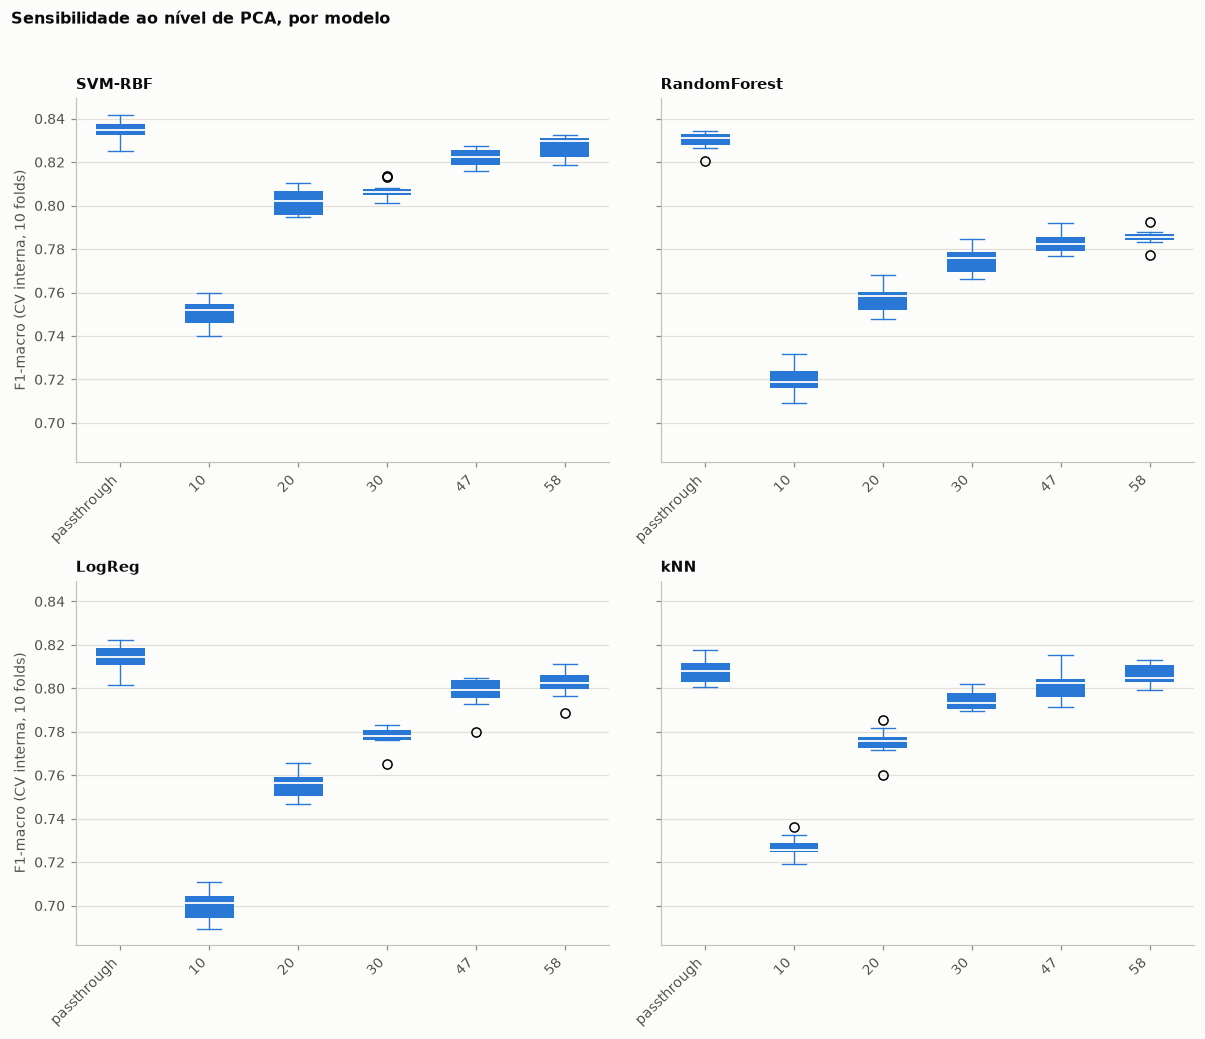

In [ ]:
n_modelos = len(modelos_com_pca)
ncols = 2
nrows = int(np.ceil(n_modelos / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(11, 4.6 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()  # garante lista 1D mesmo se nrows=1 ou n_modelos=1

for ax, m in zip(axes, modelos_com_pca):
    sub = resultados_pca[resultados_pca["modelo"] == m]
    configs = ["passthrough"] + sorted(
        (c for c in sub["pca_config"].unique() if c != "passthrough"),
        key=lambda c: int(c.split("_")[1]),
    )
    dados_box = [sub.loc[sub["pca_config"] == c, "f1_macro_cv_interno"] for c in configs]

    ax.boxplot(
        dados_box, widths=0.55, patch_artist=True,
        medianprops=dict(color=SURFACE, linewidth=1.2),
        whiskerprops=dict(color=AZUL, linewidth=0.9),
        capprops=dict(color=AZUL, linewidth=0.9),
        boxprops=dict(facecolor=AZUL, edgecolor="none"),
    )
    ax.set_xticks(range(1, len(configs) + 1))
    ax.set_xticklabels([c.replace("pca_", "") for c in configs], rotation=45, ha="right")
    ax.set_title(m, loc="left", fontsize=10, weight="bold")
    ax.grid(axis="x", visible=False)

for ax in axes[n_modelos:]:
    ax.set_visible(False)

for i in range(0, n_modelos, ncols):
    axes[i].set_ylabel("F1-macro (CV interna, 10 folds)")

fig.suptitle("Sensibilidade ao nível de PCA, por modelo", x=0.01, ha="left",
             fontsize=10.5, weight="bold", y=1.02)

plt.tight_layout()
plt.show()

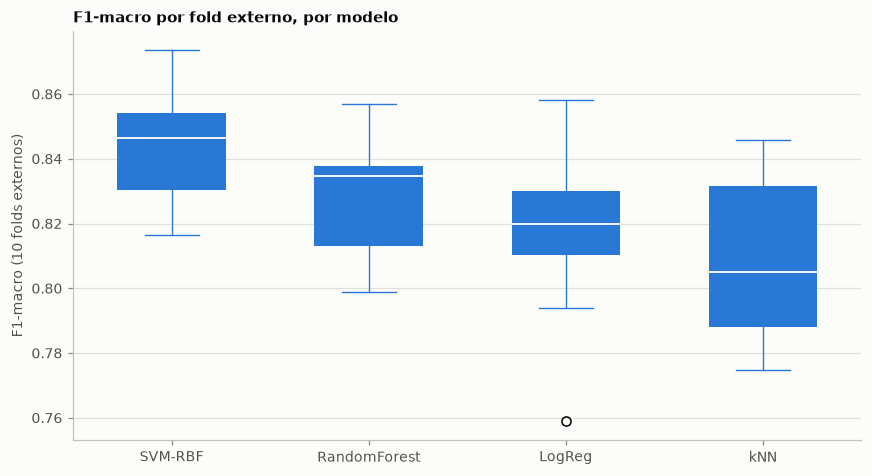

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.4))
# Excluimos o Dummy, que é apenas referência e não é comparável aos demais.
dados_box = [resultados_fold.loc[resultados_fold["modelo"] == m, "f1_macro"] for m in ordem_modelos[:-1]]

ax.boxplot(
    dados_box, widths=0.55, patch_artist=True,
    medianprops=dict(color=SURFACE, linewidth=1.2),
    whiskerprops=dict(color=AZUL, linewidth=0.9),
    capprops=dict(color=AZUL, linewidth=0.9),
    boxprops=dict(facecolor=AZUL, edgecolor="none"),
)
ax.set_xticks(range(1, len(ordem_modelos[:-1]) + 1))
ax.set_xticklabels(ordem_modelos[:-1])
ax.set_title("F1-macro por fold externo, por modelo", loc="left", fontsize=10, weight="bold")
ax.set(ylabel="F1-macro (10 folds externos)")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

In [62]:
from scipy.stats import friedmanchisquare, wilcoxon
import scikit_posthocs as sp
matriz = resultados_fold.pivot(index="fold", columns="modelo", values="f1_macro")[ordem_modelos]
estat, p_valor = friedmanchisquare(*[matriz[c] for c in matriz.columns])

print(f"Teste de Friedman entre os {len(ordem_modelos)} modelos: "
      f"estatística={estat:.3f} | p={p_valor:.4f}")

if p_valor < 0.05:
    posthoc = sp.posthoc_nemenyi_friedman(matriz.to_numpy())
    posthoc.index = posthoc.columns = matriz.columns
    print("\np-valores do post-hoc de Nemenyi (todos os pares de modelos):")
    print(posthoc.round(4).to_string())
else:
    print("Sem evidência de diferença entre os modelos (p >= 0,05) "
          "— resultados estatisticamente equivalentes dado o ruído entre folds.")

Teste de Friedman entre os 5 modelos: estatística=30.160 | p=0.0000

p-valores do post-hoc de Nemenyi (todos os pares de modelos):
modelo        SVM-RBF  RandomForest  LogReg     kNN   Dummy
modelo                                                     
SVM-RBF        1.0000        0.6184  0.1141  0.0248  0.0000
RandomForest   0.6184        1.0000  0.8600  0.5261  0.0013
LogReg         0.1141        0.8600  1.0000  0.9800  0.0377
kNN            0.0248        0.5261  0.9800  1.0000  0.1571
Dummy          0.0000        0.0013  0.0377  0.1571  1.0000


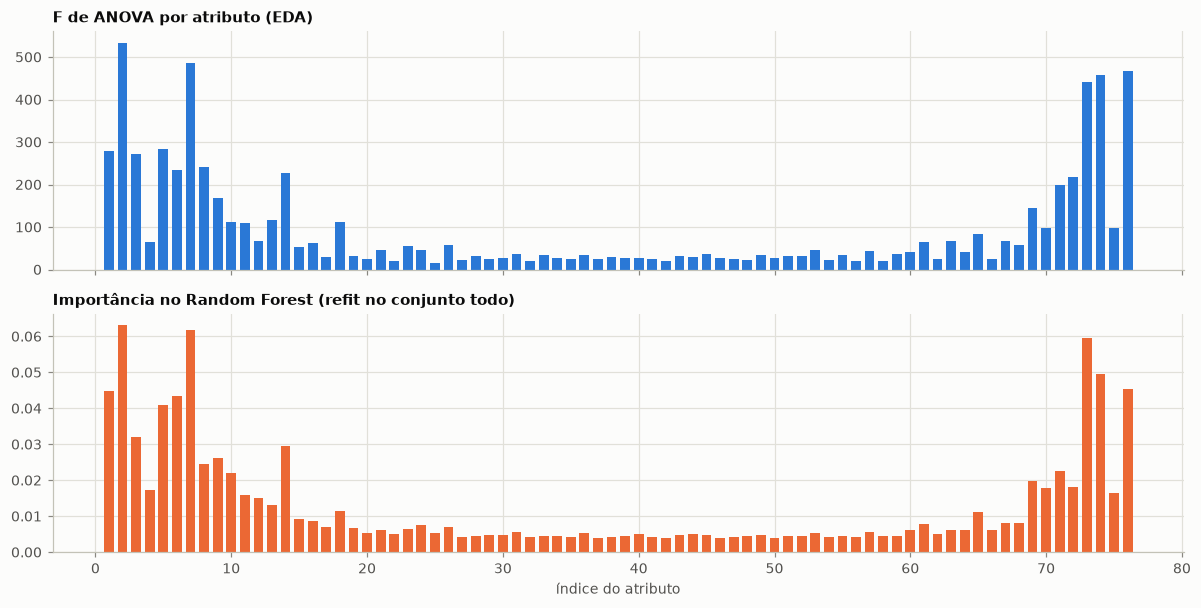

Correlação (Pearson) entre F-ANOVA e importância do RF: 0.971


In [63]:
# Refit do RandomForest no conjunto inteiro (fora do loop de avaliação) para
# extrair feature_importances_ e comparar com o F-ANOVA da EDA.
pipe_rf, grade_rf = MODELOS["RandomForest"]
busca_rf = GridSearchCV(pipe_rf, grade_rf, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
busca_rf.fit(X, y)
melhor_rf = busca_rf.best_estimator_
importancias = melhor_rf.named_steps["clf"].feature_importances_

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
ax1.bar(range(1, n_attr + 1), F_score, color=AZUL, width=0.72)
ax1.set_title("F de ANOVA por atributo (EDA)", loc="left", fontsize=10, weight="bold")

ax2.bar(range(1, n_attr + 1), importancias, color=LARANJA, width=0.72)
ax2.set_title("Importância no Random Forest (refit no conjunto todo)",
                loc="left", fontsize=10, weight="bold")
ax2.set_xlabel("índice do atributo")

plt.tight_layout()
plt.show()

corr_f_imp = np.corrcoef(F_score, importancias)[0, 1]
print(f"Correlação (Pearson) entre F-ANOVA e importância do RF: {corr_f_imp:.3f}")

#### Discussão dos resultados

*(preencher após executar as células acima — roteiro do que responder, com base no que foi produzido)*

- **Qual modelo venceu?** Ler pela tabela de `resumo` (ordenada por F1-macro), mas confirmar pelo boxplot: um modelo com média um pouco maior e dispersão bem maior entre folds pode não ser realmente "melhor" — é para isso que serve o teste de Friedman/post-hoc.
- **Os resultados foram estáveis?** Dois sinais: (1) o desvio-padrão do F1-macro entre os 10 folds externos, por modelo; (2) a variação dos `best_params_` fold a fold (célula de estabilidade de hiperparâmetros) — hiperparâmetro que muda muito de fold para fold é sinal de grade mal calibrada ou de problema pouco definido nessa região.
- **O PCA ajudou?** Ver quantos folds, por modelo, escolheram PCA ativo vs. `passthrough`. Se `passthrough` venceu na maioria dos folds e modelos, isso responde empiricamente à pergunta deixada em aberto na EDA: o PCA (redução linear) não compensa, apesar da dependência não linear detectada via dCor.
- **A não linearidade foi aproveitável?** Comparar `LogReg` (linear) contra `SVM-RBF`/`RandomForest` (não lineares) usando o teste estatístico, não só a diferença de médias. Um ganho pequeno e não significativo sugere que a dependência não linear existe (dCor) mas não é muito útil para discriminar os dígitos; um ganho grande e significativo sugere o oposto.
- **Ligação com a EDA:** a correlação entre a importância do RandomForest e o F-ANOVA (última célula) indica se árvores e um teste estatístico simples concordam sobre quais atributos importam — se sim, reforça que a dificuldade do problema está mesmo na sobreposição das classes (silhouette 0,038), não na escolha de atributos.

## **Analisando os erros**

Aqui focaremos em analisar onde as técnicas estão errando e tentar entender por que esses erros estão ocorrendo. Todo mundo erra a mesma coisa? Que características têm as instâncias em que os maiores erros são cometidos? Faça discussões.

## **Conclusões**

Quais são suas conclusões sobre os experimentos realizados? Resuma o que foi alcançado no trabalho e tente propor estratégias para trabalhos futuros com esses dados. Agradeço também se puderem dar um feedback sobre o que acharam do trabalho. E declarem explicitamente o uso de ferramentas de LLM para auxílio ao desenvolvimento do trabalho.

## **Referências**

Inclua aqui as referências que tiver consultado/usado